## Section 2 – Task 2: day-ahead hourly energy forecast per station

At the end of a day we want the next day's energy use for every station, hour by hour. We first set up the evaluation: a chronological 70/30 split and the naive "average weekday" baseline. We then train two models on lag and calendar features, a linear regression and gradient-boosted trees, and score them on exactly the same test hours as the baseline.

> **Decision notes (internal – remove before hand-in)**
>
> **How to read this notebook.** Normal markdown cells are draft report text. Quote blocks like this one are our own log of decisions, alternatives we rejected and reflections. They are for the group only and should be deleted (or moved to the report where useful) before hand-in, so they do not count towards the word limit.
>
> **What the assignment asks for (Task 2):**
> - Predict energy per station for each of the next 24 hours, made at the end of the previous day.
> - Beat a naive baseline that predicts the historical average for that weekday (we must implement it and compare).
> - No shuffling: first 70% of the data for training, the rest for testing.
> - One model for all stations or one per station is our choice.
>
> **Status:** baseline, features, two models and a first round of tuning of the boosting model are done.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.utils.capture import capture_output
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

TARGET = "Energy (kWh)"
LOCAL_TZ = "America/Los_Angeles"
ONE_DAY = pd.Timedelta(days=1)

### 2.1 Station-hour table

Everything below only needs one table with one row per station and hour: `Station Name`, `Hour` (time-zone aware) and `Energy (kWh)`, where an empty value means the station was out of service. The next cell is the only one that knows where that table comes from, so a different cleaning pipeline can be swapped in by replacing it.

For now it comes from `hourly_panel` in `ev_charging_palo_alto.ipynb` (Section 1). That notebook is run once and the result is cached in `station_hours_pandas<version>.pkl`; delete the file to rebuild after the cleaning changes.

> **Decision notes (internal – remove before hand-in)**
>
> - **Why Marco's table (`introbid`) and not Dumitrita's:** it already has what forecasting needs. (1) Every station-hour is present, including hours with zero use; a table with only active hours would teach the model that demand is never zero. (2) Energy is spread over the *charging* time, not the whole plugged-in time, so a car that sits fully charged does not add energy to later hours. (3) Long silent gaps at busy stations are marked as outages (empty) instead of zero demand.
> - **The group has not yet agreed on one cleaning pipeline.** That is why the loading cell is isolated. If we switch, only that cell changes; the three `assert` lines check that the new table has the shape the rest of the notebook expects. All numbers below will change slightly.
> - **Why a cache file:** Marco's notebook does not save its tables, and we did not want to edit a teammate's notebook. `station_hours_pandas<version>.pkl` (41 MB) is in `.gitignore`. Risk: it goes stale if the cleaning changes, so delete it then. The pandas version is in the file name because a pickle saved by pandas 3 cannot be read by pandas 2 (e.g. Anaconda) and fails with a `StringDtype` error.
> - **Outage hours stay empty.** They are left out of the baseline averages, of model training and of scoring. We do not know the true demand in those hours, so counting them as zero would reward a model for predicting outages.
> - **We only forecast energy.** The table also has occupied minutes, which Task 2 does not ask for. It could become an extra feature later.

In [2]:
# --- Swappable cleaning step: must produce `panel` with the three columns below ---
# Pickles are not readable across pandas versions, so each version gets its own cache file
CACHE = Path(f"station_hours_pandas{pd.__version__}.pkl")
if not CACHE.exists():
    with capture_output():  # hide the cleaning notebook's own prints and plots
        get_ipython().run_line_magic("run", "ev_charging_palo_alto.ipynb")
    hourly_panel.to_pickle(CACHE)

panel = pd.read_pickle(CACHE)[["Station Name", "Hour", TARGET]].copy()

# What the rest of the notebook relies on
assert panel["Hour"].dt.tz is not None, "Hour must be time-zone aware"
assert not panel.duplicated(["Station Name", "Hour"]).any(), "one row per station and hour"
assert (panel[TARGET].dropna() >= 0).all(), "energy cannot be negative"

print("Station-hours:", len(panel), "| stations:", panel["Station Name"].nunique())
print("Out-of-service hours (empty):", panel[TARGET].isna().sum())

Station-hours: 1533155 | stations: 46
Out-of-service hours (empty): 14665


In [3]:
# Days, hours and weekdays follow the local Palo Alto clock, because a forecast "day" is a local day
local_time = panel["Hour"].dt.tz_convert(LOCAL_TZ)
panel["Date"] = local_time.dt.tz_localize(None).dt.normalize()  # the local calendar day, without a time
panel["Hour_Of_Day"] = local_time.dt.hour
panel["Weekday"] = local_time.dt.dayofweek  # 0 = Monday

### 2.2 Chronological 70/30 split

The data is not shuffled. We take the day before which 70% of all in-service station-hours fall, and cut there for every station at once: everything earlier is training data, everything from that day on is the test set. One shared cut-off date means no model ever sees information from the test period, and cutting at midnight keeps the test set made of whole days, which is what a day-ahead forecast predicts.

> **Decision notes (internal – remove before hand-in)**
>
> - **"First 70% of the data" = 70% of the rows, not 70% of the calendar.** The data runs from July 2011 to January 2021, so 70% of the calendar would cut around March 2018. But the network grew, so later years hold more station-hours, and 70% of the rows lands on 23 April 2019. We read "data" as observations. Either reading is defensible; ours gives the model more history.
> - **One cut-off date for all stations, not 70% per station.** With a per-station split, the test period of an old station overlaps the training period of a newer one. A model trained on all stations together would then have seen city-wide events (such as the COVID drop) that lie in another station's "future". A single date rules that out.
> - **Price of that choice:** 13 Sherman stations opened after the cut-off and have no training data. The baseline cannot predict them, so they are not part of the comparison. We report them separately in 2.7.
> - **The test set contains COVID.** It runs April 2019 to January 2021, so almost half of it is after 13 March 2020, when demand collapsed. This matters a lot for the results; see 2.7.
> - **Cut at local midnight** so that every test day is a full day.
> - **The test set is only used for the final scores.** The first two models use fixed settings. The tuning in 2.6 uses a validation slice cut from the end of the *training* period.

In [4]:
in_service = panel.dropna(subset=[TARGET])
CUTOFF = in_service["Date"].quantile(0.70).normalize()  # the first test day

train = panel[panel["Date"] < CUTOFF].copy()
test = panel[panel["Date"] >= CUTOFF].copy()

n_train = train[TARGET].notna().sum()
n_test = test[TARGET].notna().sum()
train_share = n_train / (n_train + n_test)

print("Cut-off day (first test day):", CUTOFF.date())
print(f"Train: {train['Date'].min().date()} to {train['Date'].max().date()}, {n_train} station-hours ({train_share:.1%})")
print(f"Test : {test['Date'].min().date()} to {test['Date'].max().date()}, {n_test} station-hours ({1 - train_share:.1%})")

new_stations = sorted(set(test["Station Name"]) - set(train["Station Name"]))
print(f"Stations in test with no training history: {len(new_stations)}")
print(new_stations)

assert train["Date"].max() < CUTOFF <= test["Date"].min()
assert abs(train_share - 0.70) < 0.01

Cut-off day (first test day): 2019-04-23
Train: 2011-07-29 to 2019-04-22, 1062214 station-hours (70.0%)
Test : 2019-04-23 to 2021-01-01, 456276 station-hours (30.0%)
Stations in test with no training history: 13
['PALO ALTO CA / SHERMAN 1', 'PALO ALTO CA / SHERMAN 11', 'PALO ALTO CA / SHERMAN 14', 'PALO ALTO CA / SHERMAN 15', 'PALO ALTO CA / SHERMAN 17', 'PALO ALTO CA / SHERMAN 2', 'PALO ALTO CA / SHERMAN 3', 'PALO ALTO CA / SHERMAN 4', 'PALO ALTO CA / SHERMAN 5', 'PALO ALTO CA / SHERMAN 6', 'PALO ALTO CA / SHERMAN 7', 'PALO ALTO CA / SHERMAN 8', 'PALO ALTO CA / SHERMAN 9']


### 2.3 Baseline: the average weekday

For each station, the baseline predicts an hour with the average energy that station used at that weekday and hour in the training set. So next Monday 9–10 am is predicted as the average of all training Mondays 9–10 am at that station. Out-of-service hours are left out of the averages.

Forecasts are scored with the mean absolute error (MAE) and the root mean squared error (RMSE), both in kWh per station-hour.

> **Decision notes (internal – remove before hand-in)**
>
> - **The baseline is exactly what the assignment describes:** the "average Monday" from the training set, per station. We average over the whole training period. Averaging only the most recent months would be a stronger baseline, but it is not the one we are asked to beat.
> - **Why two metrics:** MAE is the typical miss in kWh and is easy to explain. RMSE punishes large misses more, and large misses are what hurt when planning grid load. A model should win on both.
> - **Why not a percentage error (MAPE):** most station-hours have zero energy, and a percentage of zero is undefined.
> - **`evaluate` is the single scoring function** for the baseline and every model, and `scored` is the single set of test rows (in service, station has training history). Reusing both guarantees a like-for-like comparison.
> - **Observation:** the baseline is a smooth daily hill of about 4 kWh at the busiest station, while real hours jump between 0 and 8–11 kWh. An average cannot predict *which* hours are busy, only that daytime is busier. That is the room the models have to improve.

In [5]:
BASELINE_KEYS = ["Station Name", "Weekday", "Hour_Of_Day"]


def fit_baseline(train):
    """Average energy per station, weekday and hour of day (empty hours are skipped)."""
    return train.groupby(BASELINE_KEYS)[TARGET].mean().rename("Baseline")


def evaluate(actual, predicted):
    """Mean absolute error and root mean squared error, in kWh per station-hour."""
    error = predicted - actual
    return pd.Series({"MAE": error.abs().mean(), "RMSE": np.sqrt((error ** 2).mean())})


profile = fit_baseline(train)
test = test.join(profile, on=BASELINE_KEYS)

# The rows every forecast is scored on: station in service, and the station has a training history
scored = test.dropna(subset=[TARGET, "Baseline"]).copy()
print(f"Scored test station-hours: {len(scored)} of {len(test)}")

# Check: the baseline for one station/weekday/hour equals the plain training average
first = scored.iloc[0]
same_slot = (
    (train["Station Name"] == first["Station Name"])
    & (train["Weekday"] == first["Weekday"])
    & (train["Hour_Of_Day"] == first["Hour_Of_Day"])
)
assert np.isclose(first["Baseline"], train.loc[same_slot, TARGET].mean())

# Check: evaluate on a tiny example worked out by hand (errors +1 and -2)
assert np.allclose(evaluate(pd.Series([1.0, 3.0]), pd.Series([2.0, 1.0])), [1.5, np.sqrt(2.5)])

Scored test station-hours: 454108 of 459284


In [6]:
print("Baseline on the test set (kWh per station-hour):")
print(evaluate(scored[TARGET], scored["Baseline"]).round(4).to_string())

Baseline on the test set (kWh per station-hour):
MAE     1.4979
RMSE    2.1501


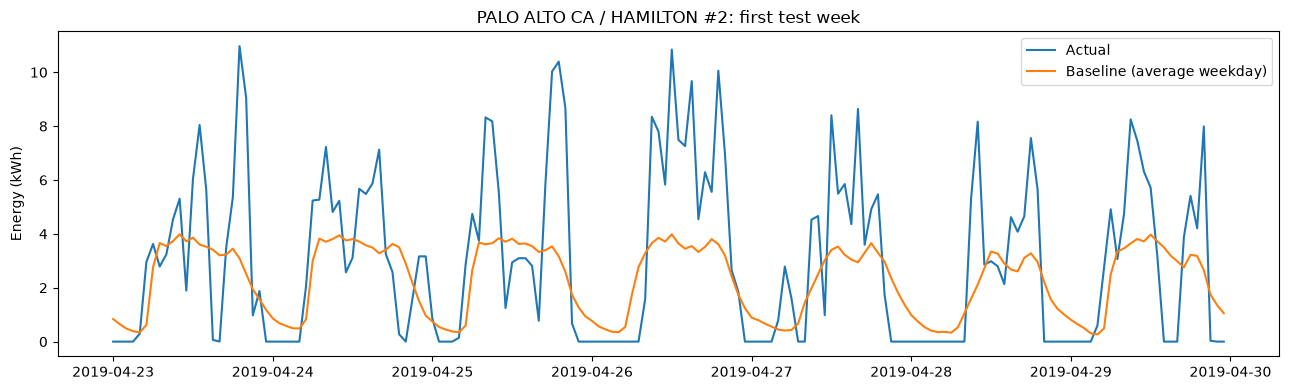

In [7]:
# First test week at the station with the most test energy
busiest_station = scored.groupby("Station Name")[TARGET].sum().idxmax()
first_week = scored[
    (scored["Station Name"] == busiest_station)
    & (scored["Date"] < CUTOFF + 7 * ONE_DAY)
]
week_hours = first_week["Hour"].dt.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(week_hours, first_week[TARGET], label="Actual")
plt.plot(week_hours, first_week["Baseline"], label="Baseline (average weekday)")
plt.title(f"{busiest_station}: first test week")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

### 2.4 Features

The forecast for day *D* is made at midnight, so a feature may only use what is known by the end of day *D-1*. Every lag is therefore counted in whole days back from the target hour: the same clock hour 1, 2, 7 and 14 days ago, the average of that hour over the last 7 days and over the last 4 same weekdays, and the station's average hourly energy yesterday and over the last week. In the test period these lags use actual observations from earlier test days, which is what the company would have at hand each midnight; the models themselves are never refitted.

Calendar features are hour, weekday, month and US federal holidays. The baseline's own prediction and the station are also given to the models, so they start from the average weekday and learn when to move away from it.

> **Decision notes (internal – remove before hand-in)**
>
> - **The rule that prevents leakage:** for hour *h* of day *D*, nothing from day *D* may be used. The shortest lag is therefore "same hour yesterday" (1 day), which is known for all 24 target hours at midnight. A lag of "1 hour ago" would be known only for the first hour of the day, so we do not use hourly lags at all. An `assert` in the code checks the 1-day lag by hand.
> - **Why these lags:** 1 and 2 days capture what the station is doing right now; 7 and 14 days capture the same weekday; the two averages smooth out the noise of single hours (one car more or less changes an hour a lot); the day-level averages tell the model whether the station as a whole is busy or quiet lately.
> - **Using actual test values in the lags is not cheating.** When forecasting day *D* in the test period, days up to *D-1* have really happened. Only the model's *parameters* are frozen at the cut-off.
> - **Why the baseline is a feature:** it summarises years of history for that station, weekday and hour in one number. It is computed from the training set only.
> - **No year or trend feature.** Trees cannot extrapolate beyond the years they have seen, and the lag averages already carry the current level.
> - **Daylight saving:** lags are looked up by local date and clock hour, not by shifting 24 rows. On the two clock-change days an hour is missing or doubled; the doubled hour is averaged and the missing one gives an empty lag.
> - **Empty lags** occur at the start of a station's life and around outages (about 0.1% of test rows). Gradient boosting handles empty values itself; for the linear model they are filled with the column average.
> - **Not used yet, candidates for later:** weather, occupied minutes, school holidays, activity at neighbouring stations.

In [8]:
def energy_same_hour(table, hourly_energy, days_ago):
    """Energy at the same station and clock hour, `days_ago` days before each row (empty if unknown)."""
    wanted = pd.MultiIndex.from_arrays([table["Station Name"], table["Date"] - days_ago * ONE_DAY, table["Hour_Of_Day"]])
    return hourly_energy.reindex(wanted).to_numpy()


def energy_whole_day(table, daily_energy, days_ago):
    """The station's average hourly energy on the day `days_ago` days before each row (empty if unknown)."""
    wanted = pd.MultiIndex.from_arrays([table["Station Name"], table["Date"] - days_ago * ONE_DAY])
    return daily_energy.reindex(wanted).to_numpy()


def build_features(panel, profile):
    table = panel[["Station Name", "Hour", "Date", "Hour_Of_Day", "Weekday", TARGET]].copy()

    # Two lookup tables: energy per station, day and clock hour, and average hourly energy per station and day.
    # Averaging per clock hour also takes care of the hour that occurs twice when the clocks go back.
    hourly_energy = table.groupby(["Station Name", "Date", "Hour_Of_Day"])[TARGET].mean()
    daily_energy = table.groupby(["Station Name", "Date"])[TARGET].mean()

    # The same clock hour on earlier days
    same_hour = pd.DataFrame(index=table.index)
    for days_ago in [1, 2, 3, 4, 5, 6, 7, 14, 21, 28]:
        same_hour[days_ago] = energy_same_hour(table, hourly_energy, days_ago)

    table["Lag_1d"] = same_hour[1]
    table["Lag_2d"] = same_hour[2]
    table["Lag_7d"] = same_hour[7]
    table["Lag_14d"] = same_hour[14]
    table["Hour_Mean_7d"] = same_hour[[1, 2, 3, 4, 5, 6, 7]].mean(axis=1)  # this hour, last 7 days
    table["Hour_Mean_4w"] = same_hour[[7, 14, 21, 28]].mean(axis=1)        # this hour, last 4 same weekdays

    # The station's overall level on earlier days
    whole_day = pd.DataFrame(index=table.index)
    for days_ago in [1, 2, 3, 4, 5, 6, 7]:
        whole_day[days_ago] = energy_whole_day(table, daily_energy, days_ago)

    table["Day_Mean_1d"] = whole_day[1]
    table["Day_Mean_7d"] = whole_day.mean(axis=1)

    # Calendar
    holidays = USFederalHolidayCalendar().holidays(table["Date"].min(), table["Date"].max())
    table["Month"] = table["Date"].dt.month
    table["Is_Holiday"] = table["Date"].isin(holidays).astype(int)

    # The baseline's prediction for this station, weekday and hour (from the training set only)
    table = table.join(profile, on=BASELINE_KEYS)

    table["Station"] = table["Station Name"].astype("category")
    return table


CATEGORY_FEATURES = ["Station", "Hour_Of_Day", "Weekday", "Month"]
NUMBER_FEATURES = ["Is_Holiday", "Baseline", "Lag_1d", "Lag_2d", "Lag_7d", "Lag_14d",
                   "Hour_Mean_7d", "Hour_Mean_4w", "Day_Mean_1d", "Day_Mean_7d"]
FEATURES = CATEGORY_FEATURES + NUMBER_FEATURES

features = build_features(panel, profile)

# Check: no feature looks into the target day. Lag_1d must equal the same station and clock hour one day earlier.
example = features.loc[scored.index[5000]]
day_before = panel[
    (panel["Station Name"] == example["Station Name"])
    & (panel["Date"] == example["Date"] - ONE_DAY)
    & (panel["Hour_Of_Day"] == example["Hour_Of_Day"])
]
assert np.isclose(example["Lag_1d"], day_before[TARGET].mean(), equal_nan=True)

# Check: the baseline feature is the same baseline we score against
assert np.allclose(features.loc[scored.index, "Baseline"], scored["Baseline"])

display(features.loc[scored.index, NUMBER_FEATURES].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Is_Holiday,454108.0,0.027,0.162,0.0,0.000,0.000,0.000,1.000
Baseline,454108.0,1.632,1.528,0.0,0.284,1.214,2.588,6.548
Lag_1d,454004.0,1.113,2.298,0.0,0.000,0.000,0.489,12.575
Lag_2d,453932.0,1.114,2.299,0.0,0.000,0.000,0.493,12.575
Lag_7d,453572.0,1.123,2.306,0.0,0.000,0.000,0.552,12.575
Lag_14d,453068.0,1.132,2.314,0.0,0.000,0.000,0.611,12.720
Hour_Mean_7d,454036.0,1.117,1.564,0.0,0.000,0.393,1.734,9.388
Hour_Mean_4w,453611.0,1.135,1.754,0.0,0.000,0.000,1.641,12.102
Day_Mean_1d,454082.0,1.113,1.122,0.0,0.082,0.836,1.762,7.128
Day_Mean_7d,454082.0,1.117,0.906,0.0,0.364,0.965,1.692,4.604


### 2.5 Models

Both models are trained once on the training set, for all stations together, on the same features.

- **Linear regression** is the simple reference: the forecast is a weighted sum of the lags and the baseline, plus a fixed shift per station, hour, weekday and month.
- **Gradient-boosted trees** can also learn interactions, for example that yesterday's demand matters more on weekdays than on weekends, or differently at different stations.

Both are fitted with squared error, so they predict the expected energy just like the baseline does. Settings are fixed in advance and were not tuned on the test set. Predictions below zero are set to zero.

> **Decision notes (internal – remove before hand-in)**
>
> - **Why two models:** the grading asks whether we used one or several models and linear or non-linear ones. The linear model also answers a useful question: how much of the gain comes from simply having lag features, and how much from a more flexible model?
> - **One model for all stations, not one per station.** Stations share the same daily and weekly rhythm, so a shared model has far more data to learn it from. Quiet stations have too little data for their own model. And a shared model can forecast a station it has never seen, which per-station models cannot. Station differences are still captured through the `Station` feature and the per-station baseline.
> - **Why gradient boosting among the non-linear options:** it works well on mixed table data like ours, trains in seconds on a million rows, accepts empty lags and a category column directly, and needs no scaling. `HistGradientBoostingRegressor` is in scikit-learn, so no extra package.
> - **Linear model details:** station, hour, weekday and month are one-hot encoded (a separate shift for each value), because "hour 23" is not 23 times "hour 1". Empty lags are filled with the column average. Plain least squares, no regularisation, so there is nothing to tune.
> - **Squared-error loss on purpose.** Most hours are zero. A model trained on absolute error would learn to predict close to zero almost everywhere: good MAE, useless for the grid. Squared error targets the average, which is also what the baseline predicts.
> - **Boosting settings here are untuned:** learning rate 0.05, at most 300 trees, scikit-learn defaults otherwise. One of those defaults is early stopping on a *random* 10% of the training rows, which is why the cell prints how many trees were actually built. A random split is not ideal for time-ordered data, so the tuned model in 2.6 switches it off and uses a chronological validation slice instead. We keep this untuned model as the reference point for the tuning.
> - **Clipping at zero:** energy cannot be negative, and both models sometimes predict slightly below zero for quiet hours.

In [9]:
is_train = (features["Date"] < CUTOFF) & features[TARGET].notna()

X_train = features.loc[is_train, FEATURES]
y_train = features.loc[is_train, TARGET]
X_test = features.loc[scored.index, FEATURES]  # the same test rows as the baseline

# Model 1: linear regression
linear_model = make_pipeline(
    ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORY_FEATURES),
        ("numbers", SimpleImputer(strategy="mean"), NUMBER_FEATURES),
    ]),
    LinearRegression(),
)
linear_model.fit(X_train, y_train)

# Model 2: gradient-boosted trees (uses the Station category and empty lags as they are)
boosting_model = HistGradientBoostingRegressor(
    categorical_features=["Station"],
    learning_rate=0.05,
    max_iter=300,
    random_state=0,
)
boosting_model.fit(X_train, y_train)

scored["Linear"] = linear_model.predict(X_test).clip(min=0)
scored["Boosting"] = boosting_model.predict(X_test).clip(min=0)

print(f"Trained on {len(X_train)} station-hours, predicted {len(X_test)}")
print("Trees built by the boosting model:", boosting_model.n_iter_)

Trained on 1062214 station-hours, predicted 454108
Trees built by the boosting model: 300


### 2.6 Tuning the boosting model

The settings of the boosting model are chosen without touching the test set. The training period is split in time once more: the model is fitted on the first 80% and each candidate setting is judged on the last 20%, the validation slice. We try two loss functions, three tree sizes and two minimum leaf sizes, and for each combination pick the number of trees with the lowest validation RMSE. The best combination is then refitted on the whole training period and scored on the test set like every other forecast.

> **Decision notes (internal – remove before hand-in)**
>
> - **Validation slice = the last 20% of the training station-hours, in time.** It runs from 26 July 2018 to 22 April 2019, the day before the test set starts. That is about nine months, so May to July are not in it; a full year would have been nicer, but it would take 27% of the training rows away from fitting. A random or shuffled validation split would let the model see days on both sides of a validation day, which makes every setting look better than it is.
> - **A single validation slice, not rolling cross-validation.** Several time-ordered folds would give a more stable choice, but cost several times the run time for a small grid whose candidates turn out to be close together. Worth revisiting only if the choice looks unstable.
> - **The baseline feature is rebuilt for tuning.** During tuning the "average weekday" profile is computed from the fit part only. Otherwise the baseline feature would already contain the validation period and look more useful than it will be on the test set.
> - **What we tune and why:**
>   - *Loss:* squared error (what we had) against Poisson. Poisson is made for non-negative data with many zeros and a variance that grows with the level, which describes hourly energy well. Both predict the expected value, so they are comparable with the baseline.
>   - *Tree size (`max_leaf_nodes`):* 15, 31 (default) or 63 leaves. Larger trees can learn finer interactions but overfit more easily.
>   - *Minimum rows per leaf (`min_samples_leaf`):* 20 (default) or 200. A larger value stops the model from fitting single odd hours.
>   - *Number of trees:* not a grid dimension. Each candidate is built with up to 1,000 trees and we read off the validation error after every tree, then keep the best count. This costs nothing extra.
> - **What we do not tune:** the learning rate stays at 0.05. A lower rate with more trees gives nearly the same model, so tuning both wastes time. The feature set is also fixed; changing features is a bigger step than tuning.
> - **Chosen by validation RMSE.** RMSE matches what the models are trained to minimise and stresses the large misses that matter for the grid. Validation MAE is shown next to it to check that the two agree.
> - **The untuned settings are one of the candidates** (squared error, 31 leaves, 20 rows per leaf), so the winner can never be worse than them on the validation slice. Whether that carries over to the test set is a separate question, answered in 2.7.
> - **Refit on all training data.** After choosing, the model is refitted on the full training period (fit part + validation slice) with the chosen settings and tree count, so it has seen the most recent year before forecasting the test period.
> - **Risk to keep in mind:** the validation period (2018–19) is normal demand, while almost half of the test set is COVID. Settings that are best in a normal year need not be best when demand collapses.
> - **Outcome of the search:** the winner is squared error, 31 leaves, at least 200 rows per leaf, 198 trees. But the twelve candidates are almost indistinguishable: validation RMSE runs from 1.8801 to 1.8835, a spread of 0.2%. All six squared-error candidates rank above all six Poisson ones on RMSE, while Poisson is slightly better on MAE (about 1.194 against 1.202), so the two metrics do not agree on the loss. We stay with RMSE as decided beforehand. The practical message is that the model is not sensitive to these settings; the default was already close to the best. The search takes about two and a half minutes to run.

In [10]:
# Split the training period in time: fit on the first 80%, validate on the last 20%
train_dates = features.loc[is_train, "Date"]
VALIDATION_START = train_dates.quantile(0.80).normalize()

# For tuning, the baseline feature may only know the fit part, not the validation slice
fit_part_of_train = train[train["Date"] < VALIDATION_START]
tuning_features = build_features(panel, fit_baseline(fit_part_of_train))

has_target = tuning_features[TARGET].notna()
in_fit = has_target & (tuning_features["Date"] < VALIDATION_START)
in_validation = has_target & (tuning_features["Date"] >= VALIDATION_START) & (tuning_features["Date"] < CUTOFF)

X_fit = tuning_features.loc[in_fit, FEATURES]
y_fit = tuning_features.loc[in_fit, TARGET]
X_validation = tuning_features.loc[in_validation, FEATURES]
y_validation = tuning_features.loc[in_validation, TARGET].to_numpy()

print(f"Fit part       : {tuning_features.loc[in_fit, 'Date'].min().date()} to {tuning_features.loc[in_fit, 'Date'].max().date()}, {in_fit.sum()} station-hours")
print(f"Validation part: {VALIDATION_START.date()} to {tuning_features.loc[in_validation, 'Date'].max().date()}, {in_validation.sum()} station-hours")

assert tuning_features.loc[in_validation, "Date"].max() < CUTOFF, "the validation slice must not touch the test set"

Fit part       : 2011-07-29 to 2018-07-25, 849023 station-hours
Validation part: 2018-07-26 to 2019-04-22, 213191 station-hours


In [11]:
MAX_TREES = 1000
LEARNING_RATE = 0.05

tuning_rows = []
for loss in ["squared_error", "poisson"]:
    for max_leaf_nodes in [15, 31, 63]:
        for min_samples_leaf in [20, 200]:
            candidate = HistGradientBoostingRegressor(
                loss=loss,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_leaf=min_samples_leaf,
                learning_rate=LEARNING_RATE,
                max_iter=MAX_TREES,
                early_stopping=False,  # we pick the number of trees ourselves, on the validation slice
                categorical_features=["Station"],
                random_state=0,
            )
            candidate.fit(X_fit, y_fit)

            # Validation error after 1 tree, 2 trees, ... up to MAX_TREES
            rmse_per_tree = []
            mae_per_tree = []
            for prediction in candidate.staged_predict(X_validation):
                error = prediction.clip(min=0) - y_validation
                rmse_per_tree.append(np.sqrt(np.mean(error ** 2)))
                mae_per_tree.append(np.mean(np.abs(error)))

            best_trees = int(np.argmin(rmse_per_tree)) + 1
            tuning_rows.append({
                "Loss": loss,
                "Leaves": max_leaf_nodes,
                "Min rows per leaf": min_samples_leaf,
                "Best trees": best_trees,
                "Validation RMSE": rmse_per_tree[best_trees - 1],
                "Validation MAE": mae_per_tree[best_trees - 1],
                "RMSE at 300 trees": rmse_per_tree[299],
            })

tuning_table = pd.DataFrame(tuning_rows).sort_values("Validation RMSE").reset_index(drop=True)

validation_baseline = evaluate(
    tuning_features.loc[in_validation, TARGET],
    tuning_features.loc[in_validation, "Baseline"],
)
print("Baseline on the validation slice (stations with a history in the fit part):")
print(validation_baseline.round(4).to_string())
print("\nCandidates, best first:")
display(tuning_table.round(4))

Baseline on the validation slice (stations with a history in the fit part):
MAE     1.4077
RMSE    2.0310

Candidates, best first:


,Loss,Leaves,Min rows per leaf,Best trees,Validation RMSE,Validation MAE,RMSE at 300 trees
0,squared_error,31,200,198,1.8801,1.2017,1.8807
1,squared_error,31,20,202,1.8804,1.2030,1.8814
2,squared_error,63,200,154,1.8807,1.2002,1.8828
3,squared_error,15,20,413,1.8808,1.2045,1.8811
4,squared_error,15,200,292,1.8808,1.2067,1.8809
5,squared_error,63,20,154,1.8811,1.2028,1.8827
6,poisson,15,200,446,1.8825,1.1960,1.8833
7,poisson,31,200,318,1.8828,1.1942,1.8828
8,poisson,15,20,430,1.8828,1.1971,1.8836
9,poisson,31,20,234,1.8831,1.1963,1.8832


In [12]:
best = tuning_table.iloc[0]
print("Chosen settings:")
print(best[["Loss", "Leaves", "Min rows per leaf", "Best trees"]].to_string())

# Refit the chosen settings on the whole training period, then predict the same test rows as before
tuned_model = HistGradientBoostingRegressor(
    loss=best["Loss"],
    max_leaf_nodes=int(best["Leaves"]),
    min_samples_leaf=int(best["Min rows per leaf"]),
    learning_rate=LEARNING_RATE,
    max_iter=int(best["Best trees"]),
    early_stopping=False,
    categorical_features=["Station"],
    random_state=0,
)
tuned_model.fit(X_train, y_train)
scored["Boosting tuned"] = tuned_model.predict(X_test).clip(min=0)

Chosen settings:
Loss                 squared_error
Leaves                          31
Min rows per leaf              200
Best trees                     198


### 2.7 Results

In [13]:
FORECASTS = ["Baseline", "Linear", "Boosting", "Boosting tuned"]


def score_forecasts(rows):
    """MAE and RMSE of every forecast on the given rows: one line per forecast."""
    return pd.DataFrame({name: evaluate(rows[TARGET], rows[name]) for name in FORECASTS}).T


results = score_forecasts(scored)
results["MAE vs baseline"] = results["MAE"] / results.loc["Baseline", "MAE"] - 1
results["RMSE vs baseline"] = results["RMSE"] / results.loc["Baseline", "RMSE"] - 1

print(f"Test set, {len(scored)} station-hours (kWh per station-hour):")
print(results.to_string(formatters={
    "MAE": "{:.4f}".format, "RMSE": "{:.4f}".format,
    "MAE vs baseline": "{:+.1%}".format, "RMSE vs baseline": "{:+.1%}".format,
}))

Test set, 454108 station-hours (kWh per station-hour):
                  MAE   RMSE MAE vs baseline RMSE vs baseline
Baseline       1.4979 2.1501           +0.0%            +0.0%
Linear         1.1560 1.8311          -22.8%           -14.8%
Boosting       1.1238 1.8153          -25.0%           -15.6%
Boosting tuned 1.1166 1.8057          -25.5%           -16.0%


In [14]:
# Before and after the COVID drop in demand
COVID_START = pd.Timestamp("2020-03-13")
before_covid = scored[scored["Date"] < COVID_START]
during_covid = scored[scored["Date"] >= COVID_START]

print(f"Before 13 March 2020 ({len(before_covid)} station-hours, mean energy {before_covid[TARGET].mean():.3f} kWh):")
print(score_forecasts(before_covid).round(3).to_string())
print(f"\nFrom 13 March 2020 ({len(during_covid)} station-hours, mean energy {during_covid[TARGET].mean():.3f} kWh):")
print(score_forecasts(during_covid).round(3).to_string())

Before 13 March 2020 (255151 station-hours, mean energy 1.586 kWh):
                  MAE   RMSE
Baseline        1.454  2.139
Linear          1.365  2.044
Boosting        1.315  2.028
Boosting tuned  1.317  2.028

From 13 March 2020 (198957 station-hours, mean energy 0.504 kWh):
                  MAE   RMSE
Baseline        1.555  2.164
Linear          0.888  1.516
Boosting        0.878  1.498
Boosting tuned  0.859  1.472


In [15]:
# Per station: do the models win everywhere, or only on average?
mae_by_station = scored.groupby("Station Name")[[TARGET] + FORECASTS].apply(lambda rows: score_forecasts(rows)["MAE"])
rmse_by_station = scored.groupby("Station Name")[[TARGET] + FORECASTS].apply(lambda rows: score_forecasts(rows)["RMSE"])

for name in ["Linear", "Boosting", "Boosting tuned"]:
    lower_mae = (mae_by_station[name] < mae_by_station["Baseline"]).sum()
    lower_rmse = (rmse_by_station[name] < rmse_by_station["Baseline"]).sum()
    print(f"{name}: lower MAE than the baseline at {lower_mae} of {len(mae_by_station)} stations, lower RMSE at {lower_rmse}")

print("\nMAE per station (kWh per station-hour):")
display(mae_by_station.sort_values("Baseline", ascending=False).round(3))

Linear: lower MAE than the baseline at 33 of 33 stations, lower RMSE at 33
Boosting: lower MAE than the baseline at 33 of 33 stations, lower RMSE at 33
Boosting tuned: lower MAE than the baseline at 33 of 33 stations, lower RMSE at 33

MAE per station (kWh per station-hour):


MAE,Baseline,Linear,Boosting,Boosting tuned
Station Name,,,,
PALO ALTO CA / WEBSTER #2,2.358,1.559,1.557,1.536
PALO ALTO CA / WEBSTER #1,2.336,1.811,1.843,1.830
PALO ALTO CA / HAMILTON #2,2.133,1.865,1.749,1.751
PALO ALTO CA / WEBSTER #3,2.123,1.410,1.384,1.336
PALO ALTO CA / HIGH #1,2.086,1.346,1.245,1.227
PALO ALTO CA / HIGH #3,1.997,1.585,1.590,1.581
PALO ALTO CA / TED THOMPSON #1,1.989,1.558,1.551,1.555
PALO ALTO CA / HIGH #2,1.833,1.344,1.334,1.327
PALO ALTO CA / CAMBRIDGE #1,1.803,1.429,1.398,1.383


In [16]:
# The stations that opened after the cut-off. The baseline has no history for them,
# so they are not part of the comparison above, but the models can still forecast them from their lags.
new_rows = features[
    features["Station Name"].isin(new_stations)
    & (features["Date"] >= CUTOFF)
    & features[TARGET].notna()
]
new_linear = pd.Series(linear_model.predict(new_rows[FEATURES]).clip(min=0), index=new_rows.index)
new_boosting = pd.Series(boosting_model.predict(new_rows[FEATURES]).clip(min=0), index=new_rows.index)
new_tuned = pd.Series(tuned_model.predict(new_rows[FEATURES]).clip(min=0), index=new_rows.index)
always_zero = pd.Series(0.0, index=new_rows.index)

print(f"New stations: {len(new_rows)} station-hours, mean energy {new_rows[TARGET].mean():.3f} kWh")
print(pd.DataFrame({
    "Always zero": evaluate(new_rows[TARGET], always_zero),
    "Linear": evaluate(new_rows[TARGET], new_linear),
    "Boosting": evaluate(new_rows[TARGET], new_boosting),
    "Boosting tuned": evaluate(new_rows[TARGET], new_tuned),
}).T.round(3).to_string())

New stations: 2168 station-hours, mean energy 0.240 kWh


                  MAE   RMSE
Always zero     0.240  1.093
Linear          0.727  1.165
Boosting        0.310  1.091
Boosting tuned  0.313  1.077


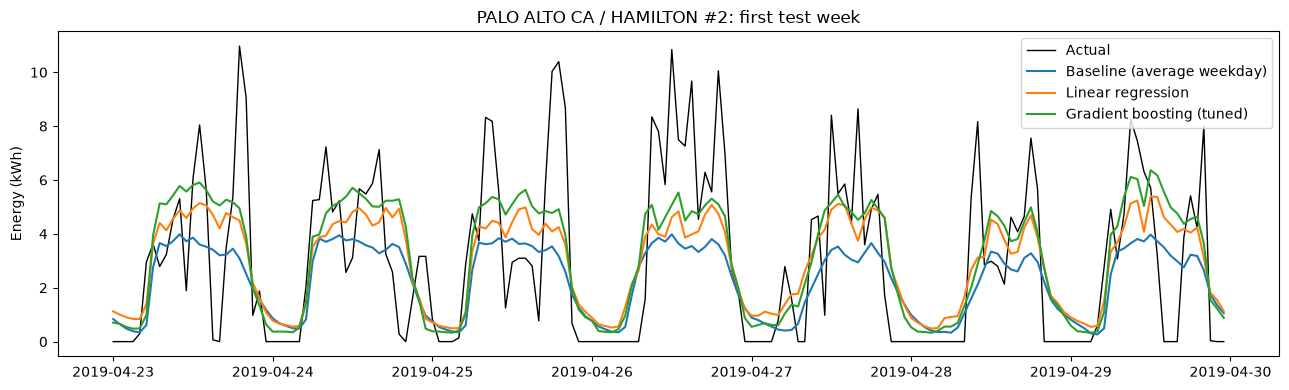

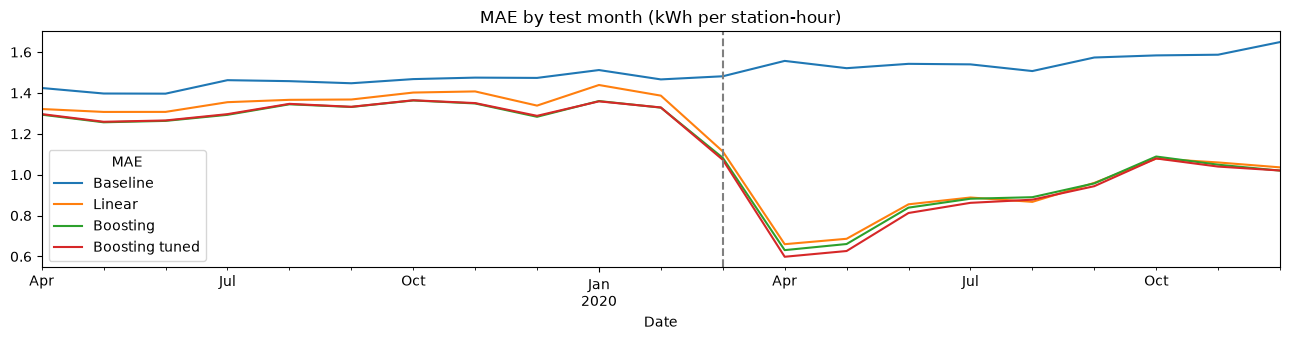

In [17]:
# Same station and week as in 2.3, now with the models
first_week = scored[
    (scored["Station Name"] == busiest_station)
    & (scored["Date"] < CUTOFF + 7 * ONE_DAY)
]
week_hours = first_week["Hour"].dt.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(week_hours, first_week[TARGET], label="Actual", color="black", linewidth=1)
plt.plot(week_hours, first_week["Baseline"], label="Baseline (average weekday)")
plt.plot(week_hours, first_week["Linear"], label="Linear regression")
plt.plot(week_hours, first_week["Boosting tuned"], label="Gradient boosting (tuned)")
plt.title(f"{busiest_station}: first test week")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

# Error per month of the test period (the last month is a single day, so it is left out)
mae_by_month = scored.groupby(scored["Date"].dt.to_period("M"))[[TARGET] + FORECASTS].apply(
    lambda rows: score_forecasts(rows)["MAE"]
)
mae_by_month.iloc[:-1].plot(figsize=(13, 3.5), title="MAE by test month (kWh per station-hour)")
plt.axvline(pd.Period("2020-03", "M"), color="grey", linestyle="--")
plt.tight_layout()
plt.show()

#### Error by hour of day

The same test scores, split by the local clock hour being forecast. The dashed line is the average energy actually used in that hour, to show how large the errors are compared with the demand.

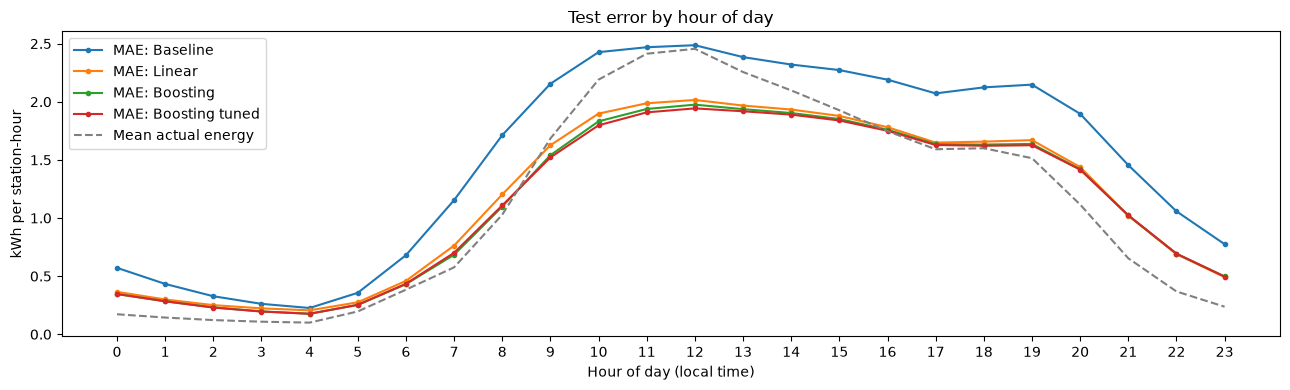

MAE,Baseline,Linear,Boosting,Boosting tuned,Mean energy,Tuned vs baseline
Hour_Of_Day,,,,,,
0,0.572,0.365,0.347,0.346,0.172,-0.394
1,0.433,0.299,0.284,0.284,0.144,-0.345
2,0.327,0.251,0.231,0.230,0.122,-0.298
3,0.262,0.223,0.197,0.196,0.108,-0.253
4,0.226,0.206,0.177,0.176,0.100,-0.220
5,0.357,0.275,0.253,0.254,0.196,-0.289
6,0.680,0.460,0.431,0.434,0.384,-0.362
7,1.154,0.763,0.684,0.701,0.576,-0.393
8,1.712,1.203,1.098,1.108,1.029,-0.353


Hours 8-19 hold 84.3% of the test energy

Hours 8-19:
                  MAE   RMSE
Baseline        2.230  2.742
Linear          1.772  2.315
Boosting        1.728  2.298
Boosting tuned  1.713  2.282

Hours 20-7:
                  MAE   RMSE
Baseline        0.766  1.315
Linear          0.540  1.161
Boosting        0.520  1.145
Boosting tuned  0.521  1.145


In [18]:
mae_by_hour = scored.groupby("Hour_Of_Day")[[TARGET] + FORECASTS].apply(lambda rows: score_forecasts(rows)["MAE"])
mean_energy_by_hour = scored.groupby("Hour_Of_Day")[TARGET].mean()

plt.figure(figsize=(13, 4))
for name in FORECASTS:
    plt.plot(mae_by_hour.index, mae_by_hour[name], marker="o", markersize=3, label=f"MAE: {name}")
plt.plot(mean_energy_by_hour.index, mean_energy_by_hour, color="grey", linestyle="--", label="Mean actual energy")
plt.title("Test error by hour of day")
plt.xlabel("Hour of day (local time)")
plt.ylabel("kWh per station-hour")
plt.xticks(range(24))
plt.legend()
plt.tight_layout()
plt.show()

hour_table = mae_by_hour.copy()
hour_table["Mean energy"] = mean_energy_by_hour
hour_table["Tuned vs baseline"] = hour_table["Boosting tuned"] / hour_table["Baseline"] - 1
display(hour_table.round(3))

daytime = scored[scored["Hour_Of_Day"].between(8, 19)]
night = scored[~scored["Hour_Of_Day"].between(8, 19)]
print(f"Hours 8-19 hold {daytime[TARGET].sum() / scored[TARGET].sum():.1%} of the test energy")
print("\nHours 8-19:")
print(score_forecasts(daytime).round(3).to_string())
print("\nHours 20-7:")
print(score_forecasts(night).round(3).to_string())

> **Decision notes (internal – remove before hand-in)**
>
> - **Why this breakdown:** one overall MAE hides when the forecasts are good or bad. The grid operator cares most about the daytime peak, so we want to know whether the models help there or only in the quiet hours.
> - **Why MAE and not RMSE here:** MAE is in plain kWh and can be set directly next to the mean energy of the hour. RMSE by hour tells the same story; the day/night summary under the table shows both.
> - **Why the mean actual energy is drawn in:** an error of 0.3 kWh means something different at 3 am (mean 0.11) than at noon (mean 2.46). Without that line the night looks "solved" when it is not.
> - **Day/night cut at 8–19:** chosen by eye from the demand curve; those twelve hours hold 84% of the test energy. It is only a summary, not a modelling choice.
> - **What we see:**
>   - *The error follows the demand.* All forecasts are worst around noon (tuned boosting MAE 1.94 at 12, where the mean is 2.46) and best at 4 am (0.18, mean 0.10).
>   - *The models help in every hour.* Tuned boosting is 19–39% below the baseline in each of the 24 hours.
>   - *The gain is smallest where it matters most.* In the early afternoon (13–15) the improvement is about 19%; at night and in the morning ramp (0, 7) it is close to 39%. Over hours 8–19 the MAE falls from 2.23 to 1.71 (−23%), over the other hours from 0.77 to 0.52 (−32%).
>   - *At night the error is larger than the demand itself.* Between midnight and 5 am the MAE is roughly twice the mean energy. Night charging is a rare event: the model predicts a small amount every night and is wrong either way. In daytime the MAE is somewhat below the mean.
>   - *Boosting beats the linear model mainly in the morning ramp and around midday* (hour 7: 0.70 against 0.76). From 21 to 23 the two are equal. So the non-linear model earns its small advantage when demand is rising, which is plausibly where interactions (weekday × hour × recent level) matter.
> - **For the report:** the honest statement is that the daytime peak remains hard to predict hour by hour for a single station. The stronger practical message comes from summing over all stations per hour, which is done in the next part.

#### Error for all stations together

The grid sees the sum of all stations, not each one separately. Here the actual energy and every forecast are added up over the stations for each hour, and the totals are scored in the same way. To compare the two levels, the MAE is also shown as a share of the mean energy at that level.

In [19]:
# One row per hour: total actual energy and total forecast energy over all scored stations
city = scored.groupby("Hour")[[TARGET] + FORECASTS].sum()
city_local_time = city.index.tz_convert(LOCAL_TZ)
city["Date"] = city_local_time.tz_localize(None).normalize()
city["Hour_Of_Day"] = city_local_time.hour
stations_per_hour = scored.groupby("Hour")["Station Name"].nunique()

print(f"{len(city)} hours, on average {stations_per_hour.mean():.1f} stations summed per hour")


def score_with_share(rows):
    """MAE and RMSE per forecast, plus the MAE as a share of the mean actual energy of these rows."""
    table = score_forecasts(rows)
    table["MAE / mean energy"] = table["MAE"] / rows[TARGET].mean()
    return table


city_scores = score_with_share(city)
city_scores["MAE vs baseline"] = city_scores["MAE"] / city_scores.loc["Baseline", "MAE"] - 1
city_scores["RMSE vs baseline"] = city_scores["RMSE"] / city_scores.loc["Baseline", "RMSE"] - 1

print(f"\nAll stations together (kWh per hour, mean total {city[TARGET].mean():.2f} kWh):")
print(city_scores.to_string(formatters={
    "MAE": "{:.3f}".format, "RMSE": "{:.3f}".format, "MAE / mean energy": "{:.1%}".format,
    "MAE vs baseline": "{:+.1%}".format, "RMSE vs baseline": "{:+.1%}".format,
}))

print(f"\nFor comparison, single stations (kWh per station-hour, mean {scored[TARGET].mean():.2f} kWh):")
print(score_with_share(scored).to_string(formatters={
    "MAE": "{:.3f}".format, "RMSE": "{:.3f}".format, "MAE / mean energy": "{:.1%}".format,
}))

14868 hours, on average 30.5 stations summed per hour

All stations together (kWh per hour, mean total 33.96 kWh):
                  MAE   RMSE MAE / mean energy MAE vs baseline RMSE vs baseline
Baseline       22.780 31.966             67.1%           +0.0%            +0.0%
Linear         11.798 16.686             34.7%          -48.2%           -47.8%
Boosting       10.814 15.314             31.8%          -52.5%           -52.1%
Boosting tuned 10.530 14.824             31.0%          -53.8%           -53.6%

For comparison, single stations (kWh per station-hour, mean 1.11 kWh):
                 MAE  RMSE MAE / mean energy
Baseline       1.498 2.150            134.7%
Linear         1.156 1.831            104.0%
Boosting       1.124 1.815            101.1%
Boosting tuned 1.117 1.806            100.4%


In [20]:
# The same city-wide scores before and after the COVID drop, and for the daytime peak
city_before_covid = city[city["Date"] < COVID_START]
city_during_covid = city[city["Date"] >= COVID_START]
city_daytime = city[city["Hour_Of_Day"].between(8, 19)]

for title, rows in [
    ("Before 13 March 2020", city_before_covid),
    ("From 13 March 2020", city_during_covid),
    ("Hours 8-19, whole test period", city_daytime),
    ("Hours 8-19, before 13 March 2020", city_daytime[city_daytime["Date"] < COVID_START]),
]:
    print(f"{title} (mean total {rows[TARGET].mean():.2f} kWh per hour):")
    print(score_with_share(rows).to_string(formatters={
        "MAE": "{:.3f}".format, "RMSE": "{:.3f}".format, "MAE / mean energy": "{:.1%}".format,
    }))
    print()

Before 13 March 2020 (mean total 51.87 kWh per hour):
                  MAE   RMSE MAE / mean energy
Baseline       13.699 18.891             26.4%
Linear         12.127 16.412             23.4%
Boosting       11.263 15.466             21.7%
Boosting tuned 11.299 15.501             21.8%

From 13 March 2020 (mean total 14.19 kWh per hour):
                  MAE   RMSE MAE / mean energy
Baseline       32.801 41.901            231.2%
Linear         11.435 16.984             80.6%
Boosting       10.318 15.145             72.7%
Boosting tuned  9.681 14.039             68.2%

Hours 8-19, whole test period (mean total 57.30 kWh per hour):
                  MAE   RMSE MAE / mean energy
Baseline       33.995 42.249             59.3%
Linear         17.670 22.039             30.8%
Boosting       16.164 20.224             28.2%
Boosting tuned 15.575 19.472             27.2%

Hours 8-19, before 13 March 2020 (mean total 87.14 kWh per hour):
                  MAE   RMSE MAE / mean energy
Baseline  

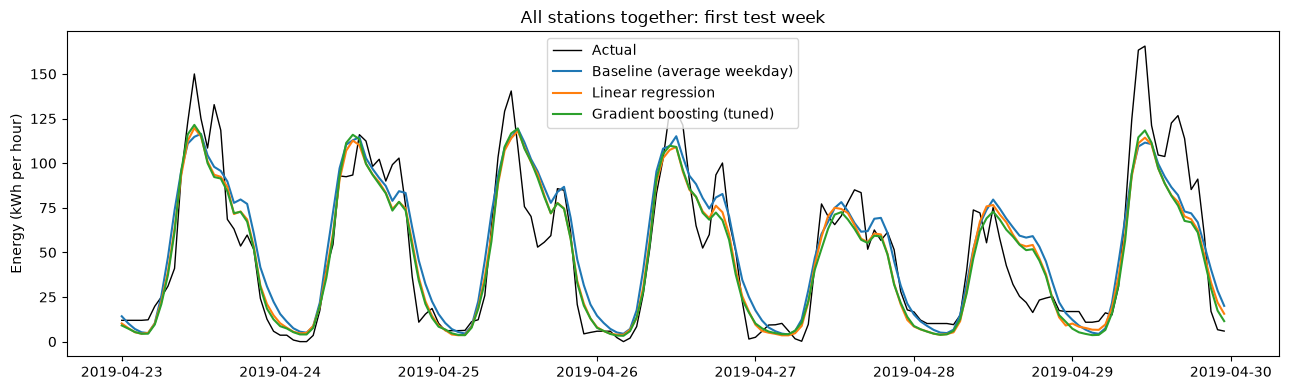

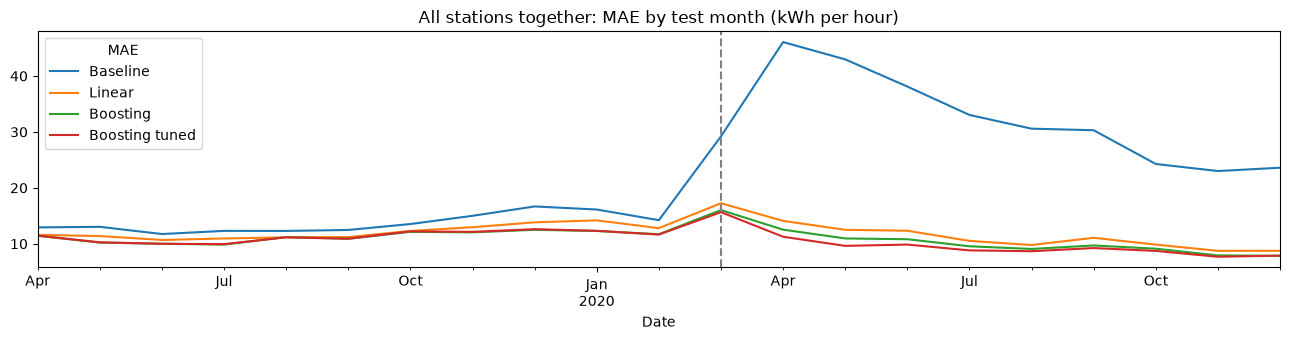

In [21]:
# City-wide total in the first test week
city_week = city[city["Date"] < CUTOFF + 7 * ONE_DAY]
city_week_hours = city_week.index.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(city_week_hours, city_week[TARGET], label="Actual", color="black", linewidth=1)
plt.plot(city_week_hours, city_week["Baseline"], label="Baseline (average weekday)")
plt.plot(city_week_hours, city_week["Linear"], label="Linear regression")
plt.plot(city_week_hours, city_week["Boosting tuned"], label="Gradient boosting (tuned)")
plt.title("All stations together: first test week")
plt.ylabel("Energy (kWh per hour)")
plt.legend()
plt.tight_layout()
plt.show()

# City-wide error per month of the test period (the last month is a single day, so it is left out)
city_mae_by_month = city.groupby(city["Date"].dt.to_period("M"))[[TARGET] + FORECASTS].apply(
    lambda rows: score_forecasts(rows)["MAE"]
)
city_mae_by_month.iloc[:-1].plot(figsize=(13, 3.5), title="All stations together: MAE by test month (kWh per hour)")
plt.axvline(pd.Period("2020-03", "M"), color="grey", linestyle="--")
plt.tight_layout()
plt.show()

> **Decision notes (internal – remove before hand-in)**
>
> - **Why this view:** the assignment says the forecast is needed "to manage the energy grid properly". The grid carries the sum of the stations, so the error of the total is the number that matters in practice. The per-station scores above remain our official comparison, because Task 2 asks for a forecast per station.
> - **No new model.** We simply add up the per-station forecasts we already have, hour by hour, and add up the actual energy the same way. Only the scored rows are summed (station in service and with a training history), so the actual total and the forecast total always cover exactly the same stations: on average 30.5 per hour. This is the total of the *scored* stations, not of the whole network; the 13 new Sherman stations are not in it.
> - **"MAE / mean energy"** is our way to compare the two levels. A MAE of 10 kWh for the total and 1.1 kWh for one station cannot be compared directly; dividing each by the mean energy at its own level can.
> - **Why the same splits as before (COVID, hours 8–19):** so the city-wide numbers can be read against the per-station ones.
> - **What we see:**
>   - *Summing makes the forecasts far more useful.* For a single station the tuned model's MAE is as large as the mean energy (100%). For the total it is 31% over the whole test period, and 22% before COVID. In the daytime peak before COVID it is 18% (MAE 15.7 kWh on a mean of 87 kWh per hour).
>   - *The advantage over the baseline is larger for the total than per station.* Over the whole test period the tuned model more than halves the baseline's error (MAE 10.5 against 22.8, −54%; RMSE 14.8 against 32.0, −54%). Per station it was −25% / −16%.
>   - *The reason:* the part of the error that is pure chance (does a car show up this hour at this station?) partly cancels when stations are summed. What does not cancel is being wrong about the general level, and that is exactly what the lag features fix and the baseline cannot.
>   - *COVID is again most of it, but not all.* From 13 March 2020 the baseline misses the total by 33 kWh per hour on a mean of 14, more than twice the demand; the tuned model by 9.7. Before COVID the tuned model is still 17.5% better on MAE (11.3 against 13.7) and 18% on RMSE (15.5 against 18.9). That is roughly double the pre-COVID gain per station (9.4% / 5.2%), and it is the fairest "normal times" number we have.
>   - *Tuning makes no difference here before COVID* (11.30 against 11.26) and helps a little after (9.7 against 10.3), the same pattern as per station.
>   - *The errors do not cancel completely.* If station errors were independent, the RMSE of a sum of about 30 stations would be about √30 ≈ 5.5 times the per-station RMSE, so roughly 11 kWh before COVID. We measure 15.5. So stations tend to be wrong in the same direction in the same hour: something city-wide (weather, events, school holidays) moves them together. This is a rough check, since stations differ in size, but it points to where new features could help.
>   - *The plot of the first test week is a sober reminder:* in a normal week the three forecasts are nearly on top of each other and all of them miss the tallest midday peaks (actual 150–165 kWh, forecast about 120).
> - **For the report:** a good way to present Task 2 is in two steps. Per station, hour by hour, demand is mostly chance and any forecast is rough. For the network as a whole, our model predicts the hourly load within about a fifth in normal times and stays usable when demand shifts, where the average-weekday baseline does not.
> - **Not done:** a model trained directly on the city total might do better still for this purpose, but it would not answer the task (a forecast per station).

#### Which features does the tuned model rely on?

For each feature, its values are shuffled across the test rows and we measure how much the RMSE of the tuned boosting model gets worse. A large increase means the model depends on that feature.

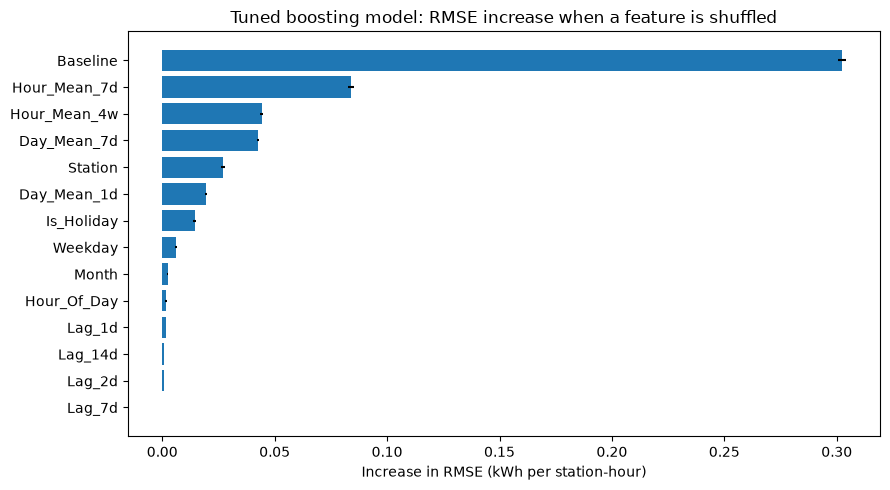

              RMSE increase  Spread over repeats
Baseline             0.3022               0.0018
Hour_Mean_7d         0.0839               0.0013
Hour_Mean_4w         0.0442               0.0006
Day_Mean_7d          0.0426               0.0006
Station              0.0270               0.0009
Day_Mean_1d          0.0195               0.0006
Is_Holiday           0.0144               0.0007
Weekday              0.0061               0.0003
Month                0.0024               0.0002
Hour_Of_Day          0.0017               0.0004
Lag_1d               0.0016               0.0001
Lag_14d              0.0007               0.0000
Lag_2d               0.0006               0.0000
Lag_7d              -0.0000               0.0001

Correlation between the number features on the sample:


,Is_Holiday,Baseline,Lag_1d,Lag_2d,Lag_7d,Lag_14d,Hour_Mean_7d,Hour_Mean_4w,Day_Mean_1d,Day_Mean_7d
Is_Holiday,1.00,0.01,-0.02,-0.00,0.02,0.03,0.01,0.02,-0.02,0.02
Baseline,0.01,1.00,0.43,0.39,0.46,0.47,0.60,0.62,0.20,0.23
Lag_1d,-0.02,0.43,1.00,0.40,0.39,0.38,0.68,0.49,0.49,0.39
Lag_2d,-0.00,0.39,0.40,1.00,0.36,0.35,0.68,0.46,0.32,0.40
Lag_7d,0.02,0.46,0.39,0.36,1.00,0.44,0.68,0.75,0.30,0.39
Lag_14d,0.03,0.47,0.38,0.35,0.44,1.00,0.55,0.76,0.28,0.35
Hour_Mean_7d,0.01,0.60,0.68,0.68,0.68,0.55,1.00,0.75,0.46,0.58
Hour_Mean_4w,0.02,0.62,0.49,0.46,0.75,0.76,0.75,1.00,0.37,0.46
Day_Mean_1d,-0.02,0.20,0.49,0.32,0.30,0.28,0.46,0.37,1.00,0.80
Day_Mean_7d,0.02,0.23,0.39,0.40,0.39,0.35,0.58,0.46,0.80,1.00


In [22]:
# Shuffle one feature at a time on a random sample of the test rows and measure the damage.
# A sample keeps this fast; five repeats per feature show how stable the result is.
sample_rows = X_test.sample(n=100_000, random_state=0)
sample_target = scored.loc[sample_rows.index, TARGET]

shuffled = permutation_importance(
    tuned_model,
    sample_rows,
    sample_target,
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=0,
)

importance = pd.DataFrame({
    "RMSE increase": shuffled.importances_mean,
    "Spread over repeats": shuffled.importances_std,
}, index=FEATURES).sort_values("RMSE increase")

plt.figure(figsize=(9, 5))
plt.barh(importance.index, importance["RMSE increase"], xerr=importance["Spread over repeats"])
plt.title("Tuned boosting model: RMSE increase when a feature is shuffled")
plt.xlabel("Increase in RMSE (kWh per station-hour)")
plt.tight_layout()
plt.show()

print(importance.sort_values("RMSE increase", ascending=False).round(4).to_string())

# How closely related the lag features are to each other (relevant for reading the plot)
print("\nCorrelation between the number features on the sample:")
display(sample_rows[NUMBER_FEATURES].corr().round(2))

> **Decision notes (internal – remove before hand-in)**
>
> - **Why permutation importance:** the scikit-learn boosting model we use has no built-in importance scores, and permutation importance has a meaning that is easy to explain: "how much worse does the forecast get if this column is scrambled?" It is measured in the same unit as our error (kWh RMSE).
> - **Measured on the test rows, on purpose.** We want to know what the model relies on when forecasting unseen days. This is a diagnostic only: nothing is selected or changed based on it, so it does not leak the test set into the model.
> - **A sample of 100,000 test rows and 5 repeats** keeps the cell fast. The spread over repeats is tiny (the error bars are barely visible), so the ranking is stable.
> - **RMSE as the score** because it is what the model was trained and tuned on. Predictions are not clipped at zero inside this calculation, which makes no visible difference.
> - **What we see:**
>   - *The baseline feature dominates.* Scrambling it raises RMSE by 0.30 kWh, more than three times the next feature. The model really does work as intended: start from the average weekday profile, then correct it.
>   - *The corrections come from the averages, not from single days.* `Hour_Mean_7d` (0.084), `Hour_Mean_4w` (0.044) and `Day_Mean_7d` (0.043) carry the recent level. The single-day lags (`Lag_1d`, `Lag_2d`, `Lag_7d`, `Lag_14d`) are close to zero.
>   - *Holidays matter more than expected* (0.014) for a flag that is on for under 3% of the rows: demand on a federal holiday looks nothing like a normal weekday.
>   - *Hour, weekday and month look unimportant* (all below 0.007), and so does `Station` relative to the baseline (0.027).
> - **How to read this without over-reading it:**
>   - *Low importance does not mean useless information.* Hour and weekday are already inside the baseline feature, which is built per station, weekday and hour. Shuffling `Hour_Of_Day` alone leaves that information intact, so the model hardly notices. The same goes for the single lags: each one is also part of an average (correlation with `Hour_Mean_7d` is about 0.68), so the model can fall back on the average when one lag is scrambled.
>   - Permutation importance therefore understates features that have close substitutes. The correlation table under the plot is there to make that visible.
>   - It shows what *this* model uses, not what drives charging demand.
> - **What we could do with it (not done):** dropping the four single-day lags would probably cost almost nothing and give a simpler model with 10 features. We keep them for now, because the feature set was fixed before tuning and removing features after looking at test-set importance would be a form of tuning on the test set. If we want the simpler model, the fair way is to compare both versions on the validation slice.

> **Decision notes (internal – remove before hand-in)**
>
> **Reflections on the results (numbers from the run with Marco's cleaning)**
>
> - **All three models beat the baseline on both metrics, at all 33 scored stations.** Baseline MAE 1.498 / RMSE 2.150. Linear 1.156 / 1.831 (−22.8% / −14.8%). Boosting 1.124 / 1.815 (−25.0% / −15.6%). Tuned boosting 1.117 / 1.806 (−25.5% / −16.0%). The requirement of the assignment is met.
> - **Tuning helped, but only marginally.** The tuned model improves on the untuned one by 0.007 kWh MAE and 0.010 kWh RMSE, about half a percent. Before COVID the two are identical (MAE 1.317 against 1.315, RMSE 2.028 for both); the whole difference comes from the COVID period (MAE 0.859 against 0.878). On the validation slice the candidates differed by only 0.2%, so a test gain of this size is not something the validation predicted, and part of it may be chance. We should present the tuned model as our final model because it was chosen by a clean procedure, not because tuning made a real difference.
> - **What actually changed between the two boosting models:** 198 trees instead of 300, at least 200 rows per leaf instead of 20, and no internal random hold-out (the untuned model set 10% of the training rows aside for early stopping, which never triggered). A smaller, more cautious model doing slightly better in the COVID period fits the idea that it leans less on fine patterns from normal years.
> - **Most of the gain over the baseline is COVID, and we should say so in the report.** From 13 March 2020 demand fell to about a third (mean 0.50 kWh per station-hour, against 1.59 before). The baseline keeps predicting pre-pandemic levels; the lags let the models follow the drop within days. In that period tuned boosting cuts MAE by 45% (1.555 to 0.859). Before COVID the gain is much smaller: MAE −9.4% (1.454 to 1.317) and RMSE −5.2% (2.139 to 2.028). The honest summary is "about 10% better in normal times, and far more robust when demand shifts".
> - **Features matter more than the model type or its settings.** The linear model already gets most of the improvement; boosting adds about 2–3 percentage points on MAE, and tuning adds half a point more. Further gains are more likely to come from new information (weather, occupancy, neighbouring stations) than from more tuning.
> - **Why the errors stay high:** before COVID the MAE (1.3) is almost as large as the mean energy (1.6). Energy in a single station-hour depends on whether one or two cars happen to plug in, which is close to random at day-ahead horizon. In the weekly plot the models predict a smooth daytime hill, while reality jumps between 0 and 8–11 kWh. The models get the *level* right (they sit above the baseline in the first test week, because the station had become busier than its long-run average), not the individual spikes. Summed over all stations the picture is much better: the tuned model's error is 31% of the mean total (22% before COVID) and less than half of the baseline's. See "Error for all stations together".
> - **New stations: no real skill.** On the 13 Sherman stations tuned boosting scores MAE 0.313 / RMSE 1.077, but simply predicting zero scores 0.240 / 1.093, because these stations were barely used (mean 0.24 kWh). The linear model is clearly worse (MAE 0.727): with no baseline value for these stations it falls back on the average baseline of all stations. We should not claim that the models handle new stations well, only that they can produce a forecast for them.
> - **The largest relative gains are at the three quietest stations** (MPL #1–#3, around −60 to −70% MAE), where the baseline still predicts activity that has stopped.
>
> **Open points**
> - Decide with the group whether to report results with and without the COVID period, or to discuss COVID only in the text.
> - Re-run everything once the group has settled on one cleaning pipeline (the tuning cell takes about two and a half minutes).
> - If we want more accuracy, add features rather than widen the tuning grid.
> - Possible simplification: drop the four single-day lags (see the feature-importance notes), checked on the validation slice.
> - Station errors move together (see the city-wide notes), so city-wide features such as weather are the most promising addition.